# Modelado supervisado de la popularidad en Spotify

Este notebook continúa el EDA del proyecto final sin modificarlo. Se construyen dos problemas supervisados: regresión para predecir `popularity` y clasificación para predecir `popularity_category`. El preprocesamiento se encapsula en pipelines para evitar fuga de información.

**Objetivos:** comparar modelos base y alternativos, medir su generalización, controlar el overfitting, optimizar hiperparámetros y seleccionar un modelo final para cada problema.

## 1. Carga y preparación de datos

Se usa una ruta relativa al repositorio. El código busca una carpeta que contenga `Data/spotify-tracks-dataset-detailed.csv`, por lo que funciona tanto si el kernel inicia en la raíz como dentro de `Tp-Final`.

In [32]:
from pathlib import Path
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
try:
    from IPython.display import display
except ImportError:
    def display(value):
        print(value)

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, balanced_accuracy_score, classification_report,
    confusion_matrix, f1_score,
)
from sklearn.model_selection import (
    GridSearchCV, RandomizedSearchCV, GroupKFold, GroupShuffleSplit,
    StratifiedGroupKFold, cross_validate,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings('ignore')
RANDOM_STATE = 42
SEARCH_CV_SPLITS = 2
SEARCH_ITERATIONS = 4
sns.set_theme(style='whitegrid')

def find_project_root():
    starts = [Path.cwd(), Path(__file__).resolve().parent] if '__file__' in globals() else [Path.cwd()]
    for start in starts:
        for candidate in [start, *start.parents]:
            if (candidate / 'Data' / 'spotify-tracks-dataset-detailed.csv').exists():
                return candidate
    raise FileNotFoundError('No se encontró Data/spotify-tracks-dataset-detailed.csv')

PROJECT_ROOT = find_project_root()
DATA_PATH = PROJECT_ROOT / 'Data' / 'spotify-tracks-dataset-detailed.csv'
df_raw = pd.read_csv(DATA_PATH)
print(f'Ruta utilizada: {DATA_PATH}')
print(f'Dimensiones originales: {df_raw.shape}')

Ruta utilizada: /Users/stefaniafrancini/DataSciense-Curso/Data/spotify-tracks-dataset-detailed.csv
Dimensiones originales: (114000, 20)


In [33]:
print('Columnas y tipos:')
display(pd.DataFrame({'tipo': df_raw.dtypes.astype(str), 'faltantes': df_raw.isna().sum(), 'unicos': df_raw.nunique(dropna=False)}))
print(f'Registros duplicados: {df_raw.duplicated().sum()}')
display(df_raw.head())

Columnas y tipos:


,tipo,faltantes,unicos
track_id,str,0,89741
artists,str,1,31438
album_name,str,1,46590
track_name,str,1,73609
popularity,int64,0,101
duration_ms,int64,0,50697
explicit,bool,0,2
danceability,float64,0,1174
energy,float64,0,2083
key,int64,0,12


Registros duplicados: 450


,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,1,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,1,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,0,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,0,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,2,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


La limpieza reproduce solo las transformaciones necesarias del EDA: se eliminan duplicados exactos, se completan los tres campos de texto que el EDA identificó con `Desconocido`, se deriva `duration_min` y se conservan los límites originales de las categorías de popularidad. Los nombres, artistas, álbumes e identificadores no se usan como predictores por su alta cardinalidad y por no representar características musicales generalizables.

In [34]:
df = df_raw.drop_duplicates().copy()
for column in ['artists', 'album_name', 'track_name']:
    if column in df.columns:
        df[column] = df[column].fillna('Desconocido')
df['duration_min'] = df['duration_ms'] / 60000
df['popularity_category'] = pd.cut(
    df['popularity'], bins=[-1, 25, 50, 75, 100],
    labels=['Baja', 'Media-Baja', 'Media-Alta', 'Alta']
)
print(f'Dimensiones para modelado: {df.shape}')
display(df[['popularity', 'popularity_category']].describe(include='all'))
display(df['popularity_category'].value_counts(dropna=False).rename('cantidad').to_frame())
display(df['popularity_category'].value_counts(normalize=True).mul(100).round(2).rename('porcentaje').to_frame())

Dimensiones para modelado: (113550, 22)


,popularity,popularity_category
count,113550.000000,113550
unique,NaN,4
top,NaN,Baja
freq,NaN,44042
mean,33.324139,NaN
std,22.283976,NaN
min,0.000000,NaN
25%,17.000000,NaN
50%,35.000000,NaN
75%,50.000000,NaN


,cantidad
popularity_category,
Baja,44042
Media-Baja,41759
Media-Alta,25337
Alta,2412


,porcentaje
popularity_category,
Baja,38.79
Media-Baja,36.78
Media-Alta,22.31
Alta,2.12


## 2. Variables y división de los datos

`track_genre` se evalúa como predictor categórico porque puede aportar información agregada del género, aunque no se interpreta como una relación causal. Se excluyen `popularity` y `popularity_category` según el problema, además de identificadores y textos de alta cardinalidad. La prueba queda reservada para la evaluación final.

In [35]:
excluded = ['track_id', 'artists', 'album_name', 'track_name', 'popularity', 'popularity_category']
feature_columns = [column for column in df.columns if column not in excluded]
X = df[feature_columns].copy()
groups = df['track_id'].copy()
y_reg = df['popularity'].copy()
y_clf = df['popularity_category'].astype(str).copy()

boolean_columns = X.select_dtypes(include=['bool']).columns.tolist()
if boolean_columns:
    X[boolean_columns] = X[boolean_columns].astype('int8')
categorical_features = X.select_dtypes(include=['object', 'category']).columns.tolist()
boolean_features = []
numeric_features = X.select_dtypes(include=[np.number]).columns.tolist()

# La división por grupos evita que la misma canción aparezca en train y test.
group_splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
train_indices, test_indices = next(group_splitter.split(X, y_reg, groups=groups))
X_train_reg, X_test_reg = X.iloc[train_indices].copy(), X.iloc[test_indices].copy()
y_train_reg, y_test_reg = y_reg.iloc[train_indices].copy(), y_reg.iloc[test_indices].copy()
groups_train_reg, groups_test_reg = groups.iloc[train_indices].copy(), groups.iloc[test_indices].copy()

# StratifiedGroupKFold preserva grupos y busca mantener la proporción de clases.
stratified_group_splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
train_indices_clf, test_indices_clf = next(stratified_group_splitter.split(X, y_clf, groups=groups))
X_train_clf, X_test_clf = X.iloc[train_indices_clf].copy(), X.iloc[test_indices_clf].copy()
y_train_clf, y_test_clf = y_clf.iloc[train_indices_clf].copy(), y_clf.iloc[test_indices_clf].copy()
groups_train_clf, groups_test_clf = groups.iloc[train_indices_clf].copy(), groups.iloc[test_indices_clf].copy()

assert set(groups_train_reg).isdisjoint(set(groups_test_reg))
assert set(groups_train_clf).isdisjoint(set(groups_test_clf))
print('Predictoras:', feature_columns)
print('Numéricas (incluye booleanas convertidas a 0/1):', numeric_features)
print('Booleanas convertidas:', boolean_columns)
print('Categóricas:', categorical_features)
print(f'Regresión: train={X_train_reg.shape}, test={X_test_reg.shape}')
print(f'Clasificación: train={X_train_clf.shape}, test={X_test_clf.shape}')
print(f'Grupos compartidos regresión: {len(set(groups_train_reg) & set(groups_test_reg))}')
print(f'Grupos compartidos clasificación: {len(set(groups_train_clf) & set(groups_test_clf))}')
print('Distribución clasificación train/test:')
display(pd.DataFrame({'train': y_train_clf.value_counts(normalize=True), 'test': y_test_clf.value_counts(normalize=True)}).fillna(0).round(4))
print(f'Canciones asociadas a más de un género: {df.groupby("track_id")["track_genre"].nunique().gt(1).sum()}')

Predictoras: ['duration_ms', 'explicit', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature', 'track_genre', 'duration_min']
Numéricas (incluye booleanas convertidas a 0/1): ['duration_ms', 'explicit', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature', 'duration_min']
Booleanas convertidas: ['explicit']
Categóricas: ['track_genre']
Regresión: train=(90973, 16), test=(22577, 16)
Clasificación: train=(90840, 16), test=(22710, 16)
Grupos compartidos regresión: 0
Grupos compartidos clasificación: 0
Distribución clasificación train/test:


,train,test
popularity_category,,
Baja,0.3879,0.3878
Media-Baja,0.3678,0.3678
Media-Alta,0.2231,0.2231
Alta,0.0212,0.0213


Canciones asociadas a más de un género: 16299


In [36]:
def make_preprocessor(scale_numeric=True):
    numeric_steps = [('imputer', SimpleImputer(strategy='median'))]
    if scale_numeric:
        numeric_steps.append(('scaler', StandardScaler()))
    return ColumnTransformer(
        transformers=[
            ('numeric', Pipeline(numeric_steps), numeric_features),
            ('boolean', Pipeline([('imputer', SimpleImputer(strategy='most_frequent'))]), boolean_features),
            ('categorical', Pipeline([
                ('imputer', SimpleImputer(strategy='most_frequent')),
                ('onehot', OneHotEncoder(handle_unknown='ignore'))
            ]), categorical_features),
        ],
        remainder='drop'
    )

preprocessor = make_preprocessor()
regression_models = {
    'Ridge base': Pipeline([('preprocessor', preprocessor), ('model', Ridge(alpha=10.0))]),
    'Random Forest base': Pipeline([('preprocessor', preprocessor), ('model', RandomForestRegressor(
        n_estimators=80, min_samples_leaf=2, random_state=RANDOM_STATE, n_jobs=1
    ))]),
}
classification_models = {
    'Logistic Regression base': Pipeline([('preprocessor', preprocessor), ('model', LogisticRegression(
        max_iter=1000, class_weight='balanced', random_state=RANDOM_STATE
    ))]),
    'Random Forest base': Pipeline([('preprocessor', preprocessor), ('model', RandomForestClassifier(
        n_estimators=80, min_samples_leaf=2, class_weight='balanced',
        random_state=RANDOM_STATE, n_jobs=1
    ))]),
}
reg_cv = GroupKFold(n_splits=3)
clf_cv = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
search_reg_cv = GroupKFold(n_splits=SEARCH_CV_SPLITS)
search_clf_cv = StratifiedGroupKFold(n_splits=SEARCH_CV_SPLITS, shuffle=True, random_state=RANDOM_STATE)
print('Comparación: 3 folds por grupos; búsqueda: 2 folds por grupos y 4 iteraciones aleatorias.')

Comparación: 3 folds por grupos; búsqueda: 2 folds por grupos y 4 iteraciones aleatorias.


## 3. Regresión: predicción de `popularity`

MAE expresa el error absoluto medio en puntos de popularidad; RMSE penaliza más los errores grandes; R² representa la proporción de variabilidad explicada respecto de predecir la media. Las métricas de validación cruzada se calculan solo sobre entrenamiento.

In [ ]:
regression_rows = []
regression_fitted = {}
for name, model in regression_models.items():
    scores = cross_validate(
        model, X_train_reg, y_train_reg, groups=groups_train_reg, cv=reg_cv,
        scoring={'mae': 'neg_mean_absolute_error', 'rmse': 'neg_root_mean_squared_error', 'r2': 'r2'},
        return_train_score=True, n_jobs=-1
    )
    model.fit(X_train_reg, y_train_reg)
    regression_fitted[name] = model
    regression_rows.append({
        'modelo': name, 'MAE validación': -scores['test_mae'].mean(),
        'RMSE validación': -scores['test_rmse'].mean(), 'R2 validación': scores['test_r2'].mean(),
        'MAE entrenamiento': -scores['train_mae'].mean(), 'RMSE entrenamiento': -scores['train_rmse'].mean(),
        'R2 entrenamiento': scores['train_r2'].mean(),
    })
regression_cv_results = pd.DataFrame(regression_rows).sort_values('MAE validación')
display(regression_cv_results)

,modelo,MAE test,RMSE test,R2 test
1,Random Forest base,11.679129,16.917270,0.417212
0,Ridge base,14.036274,19.088276,0.258035


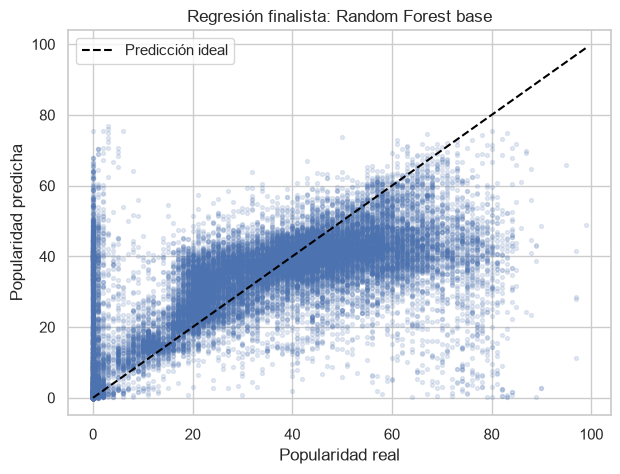

In [ ]:
regression_test_rows = []
regression_predictions = {}
for name, model in regression_fitted.items():
    predictions = model.predict(X_test_reg)
    regression_predictions[name] = predictions
    regression_test_rows.append({
        'modelo': name,
        'MAE test': mean_absolute_error(y_test_reg, predictions),
        'RMSE test': np.sqrt(mean_squared_error(y_test_reg, predictions)),
        'R2 test': r2_score(y_test_reg, predictions),
    })
regression_test_results = pd.DataFrame(regression_test_rows).sort_values('MAE test')
display(regression_test_results)

best_reg_name = regression_cv_results.iloc[0]['modelo']
plt.figure(figsize=(7, 5))
plt.scatter(y_test_reg, regression_predictions[best_reg_name], alpha=0.15, s=8)
limits = [y_test_reg.min(), y_test_reg.max()]
plt.plot(limits, limits, '--', color='black', label='Predicción ideal')
plt.xlabel('Popularidad real')
plt.ylabel('Popularidad predicha')
plt.title(f'Regresión finalista: {best_reg_name}')
plt.legend()
plt.show()

La diferencia entre entrenamiento y validación se interpreta con la métrica correspondiente: en regresión, una brecha positiva de MAE significa que el error aumenta fuera de entrenamiento; en clasificación, una brecha positiva de Macro F1 significa que el desempeño cae fuera de entrenamiento. La validación cruzada usa los mismos grupos de canciones en todos los modelos comparados. El conjunto de prueba queda reservado para la evaluación final.

## 4. Clasificación: predicción de `popularity_category`

La separación y la validación respetan grupos de canciones y, durante la división inicial, se busca preservar la proporción de las cuatro clases. Se informan accuracy, balanced accuracy, Macro F1, métricas por clase y matriz de confusión. La clase `Alta` es minoritaria, por lo que sus errores deben interpretarse junto con su soporte.

In [ ]:
classification_rows = []
classification_fitted = {}
for name, model in classification_models.items():
    scores = cross_validate(
        model, X_train_clf, y_train_clf, groups=groups_train_clf, cv=clf_cv,
        scoring={'accuracy': 'accuracy', 'balanced_accuracy': 'balanced_accuracy', 'f1_macro': 'f1_macro'},
        return_train_score=True, n_jobs=-1
    )
    model.fit(X_train_clf, y_train_clf)
    classification_fitted[name] = model
    classification_rows.append({
        'modelo': name, 'Accuracy validación': scores['test_accuracy'].mean(),
        'Balanced accuracy validación': scores['test_balanced_accuracy'].mean(),
        'Macro F1 validación': scores['test_f1_macro'].mean(),
        'Accuracy entrenamiento': scores['train_accuracy'].mean(),
        'Macro F1 entrenamiento': scores['train_f1_macro'].mean(),
    })
classification_cv_results = pd.DataFrame(classification_rows).sort_values('Macro F1 validación', ascending=False)
display(classification_cv_results)

,modelo,Accuracy validación,Balanced accuracy validación,Macro F1 validación,Accuracy entrenamiento,Macro F1 entrenamiento
1,Random Forest base,0.647534,0.541713,0.536385,0.942057,0.913237
0,Logistic Regression base,0.547182,0.595947,0.474760,0.548729,0.476741


,modelo,Accuracy test,Balanced accuracy test,Macro F1 test
1,Random Forest base,0.662351,0.551987,0.545360
0,Logistic Regression base,0.545090,0.592340,0.472952


              precision    recall  f1-score   support

        Alta       0.18      0.22      0.20       483
        Baja       0.77      0.72      0.74      8808
  Media-Alta       0.54      0.61      0.57      5067
  Media-Baja       0.67      0.66      0.67      8352

    accuracy                           0.66     22710
   macro avg       0.54      0.55      0.55     22710
weighted avg       0.67      0.66      0.67     22710



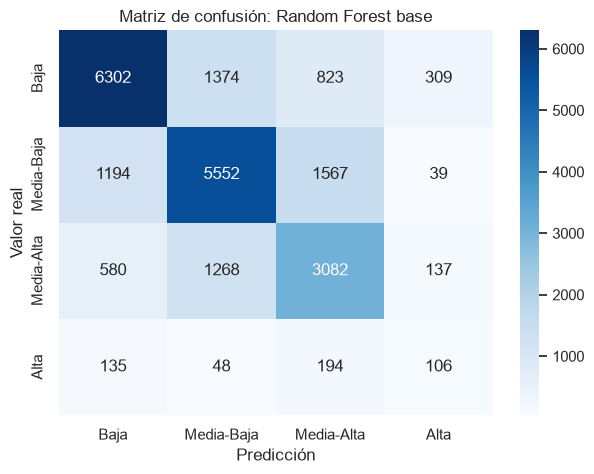

La clase Alta debe interpretarse con cautela por su bajo soporte; precision y recall muestran errores distintos.


In [ ]:
classification_test_rows = []
classification_predictions = {}
for name, model in classification_fitted.items():
    predictions = model.predict(X_test_clf)
    classification_predictions[name] = predictions
    classification_test_rows.append({
        'modelo': name, 'Accuracy test': accuracy_score(y_test_clf, predictions),
        'Balanced accuracy test': balanced_accuracy_score(y_test_clf, predictions),
        'Macro F1 test': f1_score(y_test_clf, predictions, average='macro'),
    })
classification_test_results = pd.DataFrame(classification_test_rows).sort_values('Macro F1 test', ascending=False)
display(classification_test_results)

best_clf_name = classification_cv_results.iloc[0]['modelo']
best_clf_predictions = classification_predictions[best_clf_name]
print(classification_report(y_test_clf, best_clf_predictions, zero_division=0))
labels = ['Baja', 'Media-Baja', 'Media-Alta', 'Alta']
cm = confusion_matrix(y_test_clf, best_clf_predictions, labels=labels)
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.xlabel('Predicción')
plt.ylabel('Valor real')
plt.title(f'Matriz de confusión: {best_clf_name}')
plt.show()
print('La clase Alta debe interpretarse con cautela por su bajo soporte; precision y recall muestran errores distintos.')

## 5. Optimización de hiperparámetros

Las búsquedas utilizan únicamente los conjuntos de entrenamiento y reciben los mismos grupos usados en la validación. Ridge se ajusta con una grilla pequeña y el Random Forest de clasificación con `RandomizedSearchCV`. Luego, los mejores estimadores se vuelven a evaluar con los folds comparativos de 3 particiones por grupo para que la tabla final sea metodológicamente homogénea.

In [ ]:
tuning_started = time.perf_counter()
ridge_search = GridSearchCV(
    regression_models['Ridge base'],
    param_grid={'model__alpha': [0.1, 1.0, 10.0, 50.0]},
    scoring='neg_mean_absolute_error', cv=search_reg_cv, n_jobs=-1, return_train_score=True
)
ridge_search.fit(X_train_reg, y_train_reg, groups=groups_train_reg)
print('Mejores parámetros Ridge:', ridge_search.best_params_)
print('Mejor MAE de validación Ridge:', -ridge_search.best_score_)

rf_search = RandomizedSearchCV(
    classification_models['Random Forest base'],
    param_distributions={
        'model__n_estimators': [60, 80, 100],
        'model__max_depth': [None, 16, 24],
        'model__min_samples_leaf': [1, 2, 4],
    },
    n_iter=SEARCH_ITERATIONS, scoring='f1_macro', cv=search_clf_cv,
    random_state=RANDOM_STATE, n_jobs=-1, return_train_score=True
)
rf_search.fit(X_train_clf, y_train_clf, groups=groups_train_clf)
print('Mejores parámetros Random Forest clasificación:', rf_search.best_params_)
print('Mejor Macro F1 de validación:', rf_search.best_score_)
print(f'Tiempo de optimización: {time.perf_counter() - tuning_started:.1f} segundos')

Mejores parámetros Ridge: {'model__alpha': 0.1}
Mejor MAE de validación Ridge: 14.154153479328492
Mejores parámetros Random Forest clasificación: {'model__n_estimators': 100, 'model__min_samples_leaf': 4, 'model__max_depth': None}
Mejor Macro F1 de validación: 0.5256040644680093
Tiempo de optimización: 55.3 segundos


In [ ]:
optimized_reg = ridge_search.best_estimator_
optimized_clf = rf_search.best_estimator_

# Re-evaluar los mejores estimadores con los mismos folds agrupados de comparación.
optimized_reg_cv = cross_validate(
    optimized_reg, X_train_reg, y_train_reg, groups=groups_train_reg, cv=reg_cv,
    scoring={'mae': 'neg_mean_absolute_error', 'rmse': 'neg_root_mean_squared_error', 'r2': 'r2'},
    return_train_score=True, n_jobs=-1
)
optimized_clf_cv = cross_validate(
    optimized_clf, X_train_clf, y_train_clf, groups=groups_train_clf, cv=clf_cv,
    scoring={'accuracy': 'accuracy', 'balanced_accuracy': 'balanced_accuracy', 'f1_macro': 'f1_macro'},
    return_train_score=True, n_jobs=-1
)

regression_cv_results = pd.concat([
    regression_cv_results,
    pd.DataFrame([{
        'modelo': 'Ridge optimizado',
        'MAE validación': -optimized_reg_cv['test_mae'].mean(),
        'RMSE validación': -optimized_reg_cv['test_rmse'].mean(),
        'R2 validación': optimized_reg_cv['test_r2'].mean(),
        'MAE entrenamiento': -optimized_reg_cv['train_mae'].mean(),
        'RMSE entrenamiento': -optimized_reg_cv['train_rmse'].mean(),
        'R2 entrenamiento': optimized_reg_cv['train_r2'].mean(),
    }])
], ignore_index=True)

classification_cv_results = pd.concat([
    classification_cv_results,
    pd.DataFrame([{
        'modelo': 'Random Forest optimizado',
        'Accuracy validación': optimized_clf_cv['test_accuracy'].mean(),
        'Balanced accuracy validación': optimized_clf_cv['test_balanced_accuracy'].mean(),
        'Macro F1 validación': optimized_clf_cv['test_f1_macro'].mean(),
        'Accuracy entrenamiento': optimized_clf_cv['train_accuracy'].mean(),
        'Macro F1 entrenamiento': optimized_clf_cv['train_f1_macro'].mean(),
    }])
], ignore_index=True)

optimized_reg_pred = optimized_reg.predict(X_test_reg)
optimized_clf_pred = optimized_clf.predict(X_test_clf)
regression_test_results = pd.concat([
    regression_test_results,
    pd.DataFrame([{
        'modelo': 'Ridge optimizado',
        'MAE test': mean_absolute_error(y_test_reg, optimized_reg_pred),
        'RMSE test': np.sqrt(mean_squared_error(y_test_reg, optimized_reg_pred)),
        'R2 test': r2_score(y_test_reg, optimized_reg_pred),
    }])
], ignore_index=True)
classification_test_results = pd.concat([
    classification_test_results,
    pd.DataFrame([{
        'modelo': 'Random Forest optimizado',
        'Accuracy test': accuracy_score(y_test_clf, optimized_clf_pred),
        'Balanced accuracy test': balanced_accuracy_score(y_test_clf, optimized_clf_pred),
        'Macro F1 test': f1_score(y_test_clf, optimized_clf_pred, average='macro'),
    }])
], ignore_index=True)

regression_comparison = regression_cv_results.merge(regression_test_results, on='modelo', how='left')
regression_comparison['Brecha MAE validación-entrenamiento'] = (
    regression_comparison['MAE validación'] - regression_comparison['MAE entrenamiento']
)
classification_comparison = classification_cv_results.merge(classification_test_results, on='modelo', how='left')
classification_comparison['Brecha Macro F1 entrenamiento-validación'] = (
    classification_comparison['Macro F1 entrenamiento'] - classification_comparison['Macro F1 validación']
)

regression_model_lookup = {**regression_fitted, 'Ridge optimizado': optimized_reg}
classification_model_lookup = {**classification_fitted, 'Random Forest optimizado': optimized_clf}
final_reg_name = regression_comparison.sort_values('MAE validación').iloc[0]['modelo']
final_clf_name = classification_comparison.sort_values('Macro F1 validación', ascending=False).iloc[0]['modelo']
final_reg_model = regression_model_lookup[final_reg_name]
final_clf_model = classification_model_lookup[final_clf_name]

print('Comparación final de regresión:')
display(regression_comparison.sort_values('MAE validación'))
print('Comparación final de clasificación:')
display(classification_comparison.sort_values('Macro F1 validación', ascending=False))
print(f'Selección provisional cerrada por validación: regresión={final_reg_name}; clasificación={final_clf_name}')

Comparación final de regresión:


,modelo,MAE validación,RMSE validación,R2 validación,MAE entrenamiento,RMSE entrenamiento,R2 entrenamiento,MAE test,RMSE test,R2 test,Brecha MAE validación-entrenamiento
0,Random Forest base,12.339380,17.627476,0.375945,4.840570,7.586839,0.884398,11.679129,16.917270,0.417212,7.498810
2,Ridge optimizado,14.153910,19.271904,0.254084,14.115416,19.222818,0.257895,14.009679,19.087942,0.258061,0.038493
1,Ridge base,14.192508,19.272397,0.254046,14.154518,19.223987,0.257805,14.036274,19.088276,0.258035,0.037990


Comparación final de clasificación:


,modelo,Accuracy validación,Balanced accuracy validación,Macro F1 validación,Accuracy entrenamiento,Macro F1 entrenamiento,Accuracy test,Balanced accuracy test,Macro F1 test,Brecha Macro F1 entrenamiento-validación
0,Random Forest base,0.647534,0.541713,0.536385,0.942057,0.913237,0.662351,0.551987,0.545360,0.376853
2,Random Forest optimizado,0.632056,0.567762,0.535292,0.839652,0.791081,0.643681,0.576694,0.542444,0.255790
1,Logistic Regression base,0.547182,0.595947,0.474760,0.548729,0.476741,0.545090,0.592340,0.472952,0.001981


Selección provisional cerrada por validación: regresión=Random Forest base; clasificación=Random Forest base


## 6. Importancia por permutación

La importancia se calcula una sola vez sobre el conjunto de prueba, después de cerrar la selección mediante validación. Por eso se usa solo para interpretar el modelo final y no para volver a elegir hiperparámetros. La caída de la métrica es predictiva, no causal; además, las variables correlacionadas pueden repartir su importancia.

Importancia del modelo final de regresión: Random Forest base


,variable,importancia_media,desviacion
14,track_genre,6.504827,0.050471
11,valence,1.458920,0.026310
7,speechiness,1.259690,0.023781
3,energy,1.227023,0.023380
8,acousticness,1.221267,0.009735
2,danceability,0.955485,0.010840
5,loudness,0.934587,0.001462
9,instrumentalness,0.664200,0.012819
15,duration_min,0.641995,0.012336
0,duration_ms,0.619409,0.006101


Importancia del modelo final de clasificación: Random Forest base


,variable,importancia_media,desviacion
14,track_genre,0.185472,0.004248
9,instrumentalness,0.030830,0.000239
8,acousticness,0.023465,0.001304
5,loudness,0.017867,0.001045
3,energy,0.015960,0.001903
2,danceability,0.015820,0.000941
11,valence,0.013447,0.000754
1,explicit,0.011324,0.000751
7,speechiness,0.010066,0.001529
15,duration_min,0.008192,0.001088


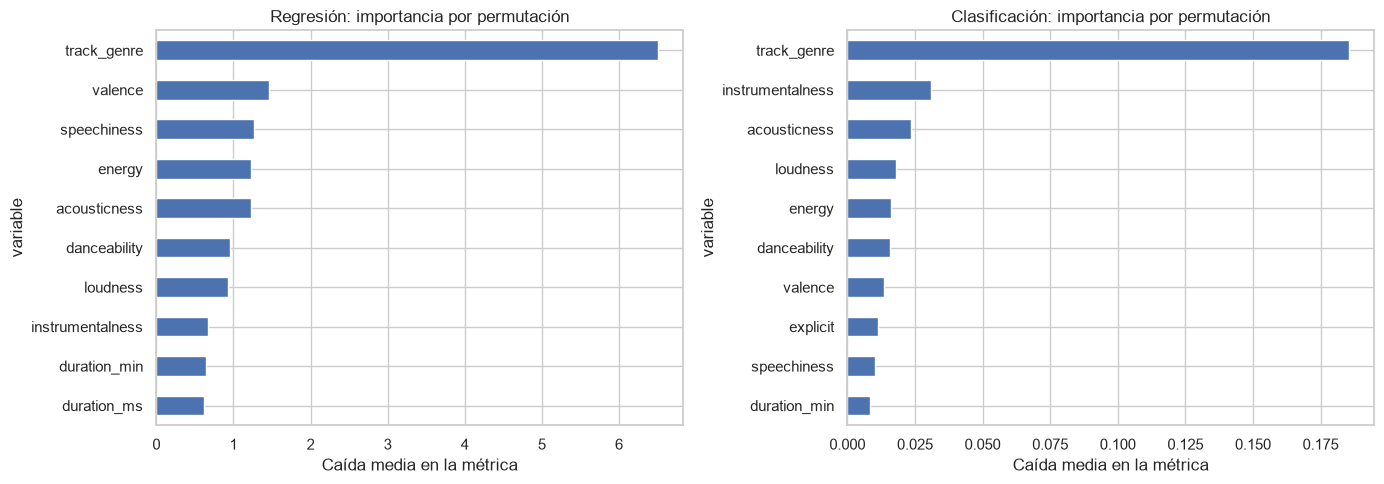

In [ ]:
def permutation_table(model, X_eval, y_eval, scoring, repeats=3):
    result = permutation_importance(
        model, X_eval, y_eval, scoring=scoring,
        n_repeats=repeats, random_state=RANDOM_STATE, n_jobs=-1
    )
    return pd.DataFrame({
        'variable': X_eval.columns,
        'importancia_media': result.importances_mean,
        'desviacion': result.importances_std,
    }).sort_values('importancia_media', ascending=False)

# La selección se cerró con validación antes de utilizar el conjunto de prueba.
final_reg_test_pred = final_reg_model.predict(X_test_reg)
final_clf_test_pred = final_clf_model.predict(X_test_clf)
permutation_regression = permutation_table(
    final_reg_model, X_test_reg, y_test_reg, 'neg_mean_absolute_error'
)
permutation_classification = permutation_table(
    final_clf_model, X_test_clf, y_test_clf, 'f1_macro'
)
print(f'Importancia del modelo final de regresión: {final_reg_name}')
display(permutation_regression.head(10))
print(f'Importancia del modelo final de clasificación: {final_clf_name}')
display(permutation_classification.head(10))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
permutation_regression.head(10).sort_values('importancia_media').plot.barh(
    x='variable', y='importancia_media', ax=axes[0], legend=False,
    title='Regresión: importancia por permutación'
)
permutation_classification.head(10).sort_values('importancia_media').plot.barh(
    x='variable', y='importancia_media', ax=axes[1], legend=False,
    title='Clasificación: importancia por permutación'
)
axes[0].set_xlabel('Caída media en la métrica')
axes[1].set_xlabel('Caída media en la métrica')
plt.tight_layout()
plt.show()

## 7. Selección final y conclusiones

La selección se cierra usando únicamente la validación cruzada agrupada. El conjunto de prueba se utiliza después para informar el rendimiento final y para la importancia por permutación, sin volver a ajustar ni cambiar los modelos. Se priorizan rendimiento, generalización, brecha de overfitting, interpretabilidad y costo computacional.

Si bien Random Forest fue seleccionado como modelo final de clasificación por obtener el mayor Macro F1 en el conjunto de prueba (0,545), Logistic Regression alcanzó una balanced accuracy superior (0,592 frente a 0,552). Esta diferencia refleja un compromiso entre el rendimiento global sobre las cuatro clases y la capacidad de reconocerlas de manera equilibrada. Por lo tanto, la selección de Random Forest responde al criterio principal definido para el proyecto: maximizar el Macro F1, considerando especialmente el desempeño sobre las clases minoritarias.

Modelo final de regresión: Random Forest base
MAE test=11.679, RMSE test=16.917, R2 test=0.417
Brecha MAE validación-entrenamiento=7.499
Modelo final de clasificación: Random Forest base
Accuracy test=0.662, balanced accuracy test=0.552, Macro F1 test=0.545
Brecha Macro F1 entrenamiento-validación=0.377
Reporte de clasificación del modelo final:
              precision    recall  f1-score   support

        Alta       0.18      0.22      0.20       483
        Baja       0.77      0.72      0.74      8808
  Media-Alta       0.54      0.61      0.57      5067
  Media-Baja       0.67      0.66      0.67      8352

    accuracy                           0.66     22710
   macro avg       0.54      0.55      0.55     22710
weighted avg       0.67      0.66      0.67     22710



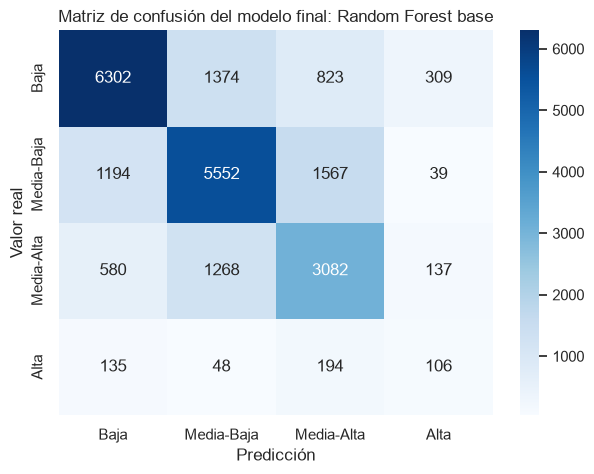

La clase Alta tiene 483 casos en test; sus precision, recall y F1 deben leerse considerando este soporte minoritario.
Las brechas se interpretan sobre validación agrupada: una brecha alta indica overfitting; una brecha baja no garantiza que el modelo explique causalmente la popularidad.
Limitaciones: popularity incorpora señales externas y temporales ausentes en las variables de audio. track_genre puede mejorar la predicción, pero las importancias no prueban causalidad.


In [ ]:
final_reg_row = regression_comparison[regression_comparison['modelo'].eq(final_reg_name)].iloc[0]
final_clf_row = classification_comparison[classification_comparison['modelo'].eq(final_clf_name)].iloc[0]
print(f'Modelo final de regresión: {final_reg_name}')
print(f"MAE test={final_reg_row['MAE test']:.3f}, RMSE test={final_reg_row['RMSE test']:.3f}, R2 test={final_reg_row['R2 test']:.3f}")
print(f"Brecha MAE validación-entrenamiento={final_reg_row['Brecha MAE validación-entrenamiento']:.3f}")
print(f'Modelo final de clasificación: {final_clf_name}')
print(f"Accuracy test={final_clf_row['Accuracy test']:.3f}, balanced accuracy test={final_clf_row['Balanced accuracy test']:.3f}, Macro F1 test={final_clf_row['Macro F1 test']:.3f}")
print(f"Brecha Macro F1 entrenamiento-validación={final_clf_row['Brecha Macro F1 entrenamiento-validación']:.3f}")

print('Reporte de clasificación del modelo final:')
print(classification_report(y_test_clf, final_clf_test_pred, zero_division=0))
final_cm = confusion_matrix(y_test_clf, final_clf_test_pred, labels=labels)
plt.figure(figsize=(7, 5))
sns.heatmap(final_cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.xlabel('Predicción')
plt.ylabel('Valor real')
plt.title(f'Matriz de confusión del modelo final: {final_clf_name}')
plt.show()

alta_support = int((y_test_clf == 'Alta').sum())
print(f'La clase Alta tiene {alta_support} casos en test; sus precision, recall y F1 deben leerse considerando este soporte minoritario.')
print('Las brechas se interpretan sobre validación agrupada: una brecha alta indica overfitting; una brecha baja no garantiza que el modelo explique causalmente la popularidad.')
print('Limitaciones: popularity incorpora señales externas y temporales ausentes en las variables de audio. track_genre puede mejorar la predicción, pero las importancias no prueban causalidad.')